# TA-07: Implementasi Q-Learning untuk Kontrol Stok Bahan Baku Kedai Kopi Kampus

Notebook ini memuat seluruh alur TA-07 dalam satu berkas: eksplorasi data, lingkungan simulasi,
pelatihan agen Q-Learning, analisis kurva pembelajaran, kebijakan optimal, dan eksperimen hiperparameter.

| Bagian | Isi | Langkah TA-07 |
|---|---|---|
| **A** | Eksplorasi dataset dan pola permintaan harian | Persiapan lingkungan |
| **B** | Lingkungan simulasi, pelatihan, kurva pembelajaran, kebijakan, perbandingan strategi, penyimpanan model | Langkah 1 sampai 4 |
| **C** | Eksperimen hiperparameter (learning rate α) | Langkah 5 |

**Prasyarat**
- Dataset ada di `data/raw/Coffe_sales.csv` (sumber: Kaggle, *Daily Coffee Transactions*).
- Berkas `src/coffee_env.py` tersedia di folder proyek.
- Pustaka Python: NumPy, Pandas, Matplotlib.

**Eksekusi:** seluruh sel dijalankan berurutan dari atas ke bawah (*Run All*). Bagian B dan C memakai keluaran Bagian A.

**Peran dataset:** dataset dipakai untuk menyusun pola permintaan pada simulasi. Agen tidak dilatih langsung dari dataset,
melainkan dari interaksi dengan lingkungan simulasi.

## Persiapan

In [29]:
import os, sys

# Cari folder utama proyek (satu tingkat di atas folder "notebooks"),
# lalu jadikan folder kerja supaya semua path di bawah ini sama di mana pun notebook dibuka.
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)
for folder in ["data/processed", "model", "static/results"]:   # buat folder keluaran jika belum ada
    os.makedirs(folder, exist_ok=True)
print("Folder kerja:", os.getcwd())

Folder kerja: c:\TA07_ML\ta07-kontrol-stok-kopi


In [30]:
import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# Warna coklat pastel (sama dengan tema web nanti)
COK_TUA = "#3F2F25"
COK     = "#8A6446"
KARAMEL = "#B98B5E"
PASIR   = "#CBB596"
SUSU    = "#E6D3BA"
KRIM    = "#F1E6D6"

plt.rcParams.update({
    "figure.facecolor": KRIM, "axes.facecolor": "#F7EFE3", "savefig.facecolor": KRIM,
    "axes.edgecolor": PASIR, "axes.labelcolor": COK_TUA, "text.color": COK_TUA,
    "xtick.color": COK_TUA, "ytick.color": COK_TUA, "grid.color": PASIR,
    "axes.titleweight": "bold", "font.size": 11,
})

from src.coffee_env import (CoffeeStockEnv, muat_permintaan, decode_state,
                            HARI, LEVEL, AKSI, N_STATE, N_AKSI)

# BAGIAN A - Eksplorasi Data: Pola Permintaan Kedai Kopi

Tujuan bagian ini adalah mengubah catatan transaksi menjadi jumlah cangkir yang terjual per hari.
Angka tersebut menjadi dasar permintaan harian pada lingkungan simulasi.

## A1. Membaca dataset

In [31]:
PATH_CSV = "data/raw/Coffe_sales.csv"
df = pd.read_csv(PATH_CSV)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (3547, 11)


,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000


## A2. Pemeriksaan kualitas data

Satu baris pada dataset mewakili satu cangkir kopi yang terjual. Pemeriksaan mencakup tipe data dan nilai kosong.

In [32]:
print(df.dtypes)
print()
print("Jumlah nilai kosong per kolom:")
print(df.isna().sum())

hour_of_day      int64
cash_type       object
money          float64
coffee_name     object
Time_of_Day     object
Weekday         object
Month_name      object
Weekdaysort      int64
Monthsort        int64
Date            object
Time            object
dtype: object

Jumlah nilai kosong per kolom:
hour_of_day    0
cash_type      0
money          0
coffee_name    0
Time_of_Day    0
Weekday        0
Month_name     0
Weekdaysort    0
Monthsort      0
Date           0
Time           0
dtype: int64


## A3. Rentang tanggal

In [33]:
df["Date"] = pd.to_datetime(df["Date"])
tgl_awal, tgl_akhir = df["Date"].min(), df["Date"].max()
hari_kalender = (tgl_akhir - tgl_awal).days + 1

print("Tanggal pertama         :", tgl_awal.date())
print("Tanggal terakhir        :", tgl_akhir.date())
print("Hari yang punya transaksi:", df["Date"].nunique())
print("Jumlah hari kalender     :", hari_kalender)

Tanggal pertama         : 2024-03-01
Tanggal terakhir        : 2025-03-23
Hari yang punya transaksi: 381
Jumlah hari kalender     : 388


## A4. Permintaan per hari

Hari tanpa transaksi bernilai permintaan 0, sehingga seluruh tanggal pada rentang dataset diisi sebelum dihitung.

In [34]:
semua_tanggal = pd.date_range(tgl_awal, tgl_akhir)
per_hari = df.groupby("Date").size().reindex(semua_tanggal, fill_value=0)

permintaan_df = pd.DataFrame({
    "tanggal": per_hari.index.strftime("%Y-%m-%d"),
    "hari_ke": per_hari.index.dayofweek,      # 0 = Senin ... 6 = Minggu
    "permintaan": per_hari.values,            # jumlah cangkir terjual pada hari itu
})
permintaan_df.head(10)

,tanggal,hari_ke,permintaan
0,2024-03-01,4,11
1,2024-03-02,5,6
2,2024-03-03,6,9
3,2024-03-04,0,4
4,2024-03-05,1,9
5,2024-03-06,2,4
6,2024-03-07,3,4
7,2024-03-08,4,8
8,2024-03-09,5,13
9,2024-03-10,6,3


## A5. Rata-rata permintaan tiap hari dalam seminggu

In [35]:
NAMA_HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]

ringkasan = permintaan_df.groupby("hari_ke")["permintaan"].agg(
    jumlah_hari="count", rata_rata="mean", median="median", minimum="min", maksimum="max"
).round(2)
ringkasan.index = NAMA_HARI
ringkasan

,jumlah_hari,rata_rata,median,minimum,maksimum
Senin,55,9.89,9.0,1,25
Selasa,55,10.40,10.0,1,24
Rabu,55,9.09,8.0,0,24
Kamis,55,9.27,9.0,0,21
Jumat,56,9.50,8.0,2,26
Sabtu,56,8.39,8.0,0,22
Minggu,56,7.48,6.0,0,24


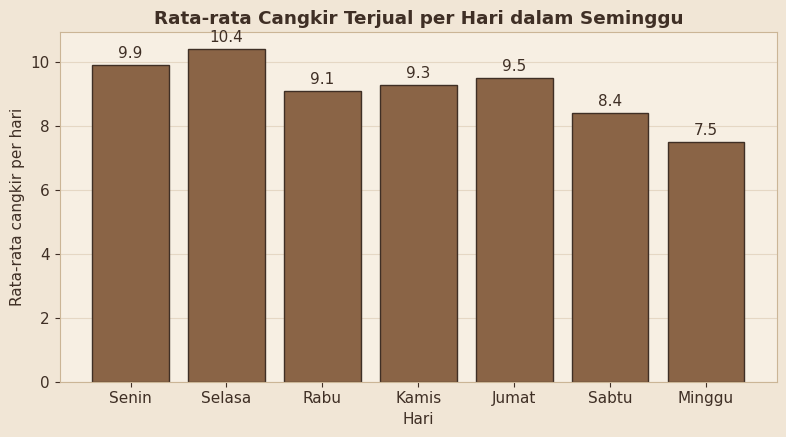

In [36]:
fig, ax = plt.subplots(figsize=(8, 4.5))
batang = ax.bar(NAMA_HARI, ringkasan["rata_rata"], color=COK, edgecolor=COK_TUA)
ax.set_title("Rata-rata Cangkir Terjual per Hari dalam Seminggu")
ax.set_ylabel("Rata-rata cangkir per hari")
ax.set_xlabel("Hari")
ax.bar_label(batang, fmt="%.1f", padding=3)
ax.grid(axis="y", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("static/results/rata_rata_permintaan.png", dpi=150)
plt.show()

## A6. Sebaran permintaan harian

Jumlah cangkir terjual berbeda dari hari ke hari walaupun harinya sama. Variasi ini menjadikan lingkungan bersifat
acak (stokastik): keputusan pemesanan harus tetap baik meskipun jumlah pelanggan berikutnya tidak pasti.

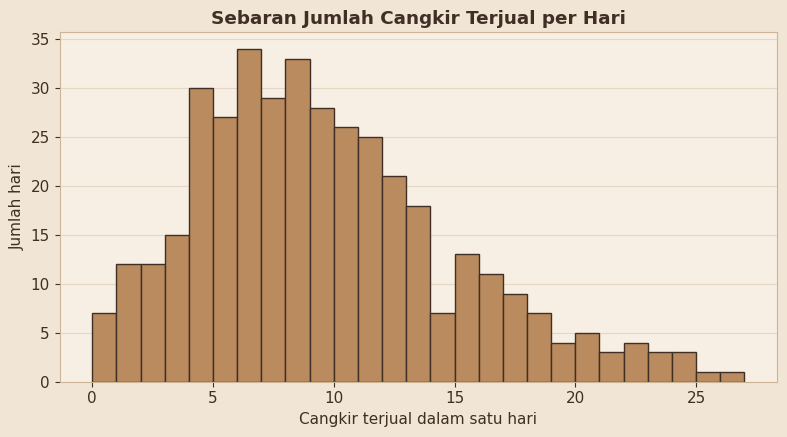

In [37]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(permintaan_df["permintaan"], bins=range(0, permintaan_df["permintaan"].max() + 2),
        color=KARAMEL, edgecolor=COK_TUA)
ax.set_title("Sebaran Jumlah Cangkir Terjual per Hari")
ax.set_xlabel("Cangkir terjual dalam satu hari")
ax.set_ylabel("Jumlah hari")
ax.grid(axis="y", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("static/results/sebaran_permintaan.png", dpi=150)
plt.show()

## A7. Jenis kopi yang paling banyak terjual

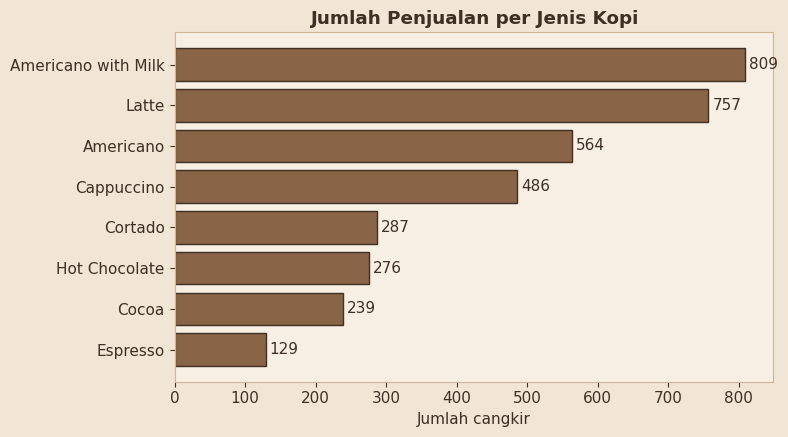

In [38]:
laku = df["coffee_name"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
batang = ax.barh(laku.index[::-1], laku.values[::-1], color=COK, edgecolor=COK_TUA)
ax.set_title("Jumlah Penjualan per Jenis Kopi")
ax.set_xlabel("Jumlah cangkir")
ax.bar_label(batang, padding=3)
plt.tight_layout()
plt.show()

## A8. Penyimpanan data permintaan

Berkas ini dibaca oleh `src/coffee_env.py`. Pada simulasi, permintaan hari Senin diambil acak dari daftar permintaan
Senin yang asli, demikian pula untuk hari-hari lainnya.

In [39]:
permintaan_df.to_csv("data/processed/permintaan_harian.csv", index=False)
print("Tersimpan: data/processed/permintaan_harian.csv", permintaan_df.shape)

Tersimpan: data/processed/permintaan_harian.csv (388, 3)


## A9. Ringkasan temuan Bagian A

In [40]:
rata_semua = permintaan_df["permintaan"].mean()
hari_ramai = ringkasan["rata_rata"].idxmax()
hari_sepi = ringkasan["rata_rata"].idxmin()
variasi = permintaan_df["permintaan"].std() / rata_semua

print(f"- Dataset mencakup {df.shape[0]:,} transaksi pada {hari_kalender} hari kalender ({tgl_awal.date()} sampai {tgl_akhir.date()}).".replace(",", "."))
print(f"- Rata-rata permintaan {rata_semua:.2f} cangkir per hari, dengan nilai tertinggi {permintaan_df['permintaan'].max()} cangkir.")
print(f"- Hari terramai: {hari_ramai} ({ringkasan.loc[hari_ramai, 'rata_rata']:.1f} cangkir). Hari tersepi: {hari_sepi} ({ringkasan.loc[hari_sepi, 'rata_rata']:.1f} cangkir).")
print(f"- Simpangan baku harian sebesar {variasi*100:.0f}% dari rata-rata, sehingga permintaan tiap hari sulit ditebak.")
print("- Konsekuensi: stok cadangan diperlukan, dan lingkungan simulasi dibuat acak berdasarkan permintaan asli tiap hari.")

- Dataset mencakup 3.547 transaksi pada 388 hari kalender (2024-03-01 sampai 2025-03-23).
- Rata-rata permintaan 9.14 cangkir per hari, dengan nilai tertinggi 26 cangkir.
- Hari terramai: Selasa (10.4 cangkir). Hari tersepi: Minggu (7.5 cangkir).
- Simpangan baku harian sebesar 58% dari rata-rata, sehingga permintaan tiap hari sulit ditebak.
- Konsekuensi: stok cadangan diperlukan, dan lingkungan simulasi dibuat acak berdasarkan permintaan asli tiap hari.


# BAGIAN B - Pelatihan Q-Learning: Kontrol Stok Kedai Kopi Kampus

Bagian ini mencakup: (1) lingkungan simulasi, (2) hiperparameter, (3) pelatihan dengan persamaan Bellman dan
strategi ε-greedy, (4) kurva pembelajaran, (5) kebijakan optimal, (6) perbandingan dengan strategi lain,
dan (7) penyimpanan model untuk aplikasi web.

## B1. Lingkungan simulasi

Aturan lingkungan ditulis pada `src/coffee_env.py` agar notebook dan aplikasi web memakai aturan yang sama.

| Komponen | Definisi |
|---|---|
| **State** | level stok (Habis, Rendah, Sedang, Tinggi) x hari (Senin sampai Minggu) = 28 state |
| **Action** | 0 = tidak memesan, 1 = pesan sedikit (+10 porsi), 2 = pesan banyak (+20 porsi) |
| **Reward** | +5 per cangkir terjual; -10 jika ada permintaan saat stok habis; -2 jika stok menumpuk (level Tinggi); -1 biaya pesan sedikit; -3 biaya pesan banyak |
| **Episode** | satu minggu (7 hari), dari Senin sampai Minggu |

**Asumsi perancangan:** kapasitas gudang 30 porsi (1 porsi = 1 cangkir); level stok Habis = 0, Rendah = 1 sampai 9,
Sedang = 10 sampai 19, Tinggi = 20 sampai 30 porsi; pesanan tiba pada pagi hari sebelum kedai buka; permintaan harian
diambil acak dari data asli hari yang sama.

In [41]:
permintaan = muat_permintaan("data/processed/permintaan_harian.csv")
env = CoffeeStockEnv(permintaan, seed=42)

# Uji satu hari secara manual untuk memastikan lingkungan bekerja
state = env.reset()
level, hari = decode_state(state)
print("State awal :", state, "->", LEVEL[level], "|", HARI[hari], "| stok sebenarnya:", env.stok)

new_state, reward, done, info = env.step(2)   # aksi 2 = pesan banyak
print("Setelah 'Pesan banyak':", info, "| reward:", reward, "| selesai:", done)

State awal : 0 -> Habis | Senin | stok sebenarnya: 0
Setelah 'Pesan banyak': {'permintaan': 10, 'terjual': 10, 'stok_akhir': 10, 'stok_habis': False, 'menumpuk': False} | reward: 47.0 | selesai: False


## B2. Hiperparameter

| Parameter | Peran |
|---|---|
| `alpha` (α) | seberapa besar nilai baru menggeser nilai lama di Q-Table |
| `gamma` (γ) | bobot reward masa depan (mendekati 1 berarti jangka panjang lebih diperhitungkan) |
| `epsilon` (ε) | peluang memilih aksi acak (eksplorasi), diturunkan bertahap |

Karena permintaan bersifat acak, α dibuat **menurun**: besar di awal agar belajar cepat, lalu mengecil
agar Q-Table stabil dan tidak mudah bergeser oleh satu hari yang kebetulan ramai atau sepi.

In [42]:
alpha_awal = 0.3              # learning rate di awal pelatihan
alpha_min = 0.01              # batas bawah learning rate
alpha_decay = 0.0002          # kecepatan penurunan learning rate
gamma = 0.9                   # discount factor
total_episodes = 20000
max_steps_per_episode = 20    # satu episode hanya 7 hari, batas ini tidak pernah tercapai

# Parameter epsilon-greedy
epsilon = 1.0                 # awal: 100% eksplorasi
max_epsilon = 1.0
min_epsilon = 0.01
decay_rate = 0.00025          # makin besar, epsilon turun makin cepat

## B3. Pelatihan Q-Learning

Setiap langkah dalam satu episode:
1. Aksi dipilih dengan **ε-greedy**: acak dengan peluang ε, selain itu aksi dengan nilai Q terbesar.
2. Aksi dijalankan di lingkungan, lalu reward dan state baru diamati.
3. Q-Table diperbarui dengan persamaan Bellman:

`Q_baru(s,a) = (1 - α) * Q(s,a) + α * [ r + γ * max Q(s',a') ]`

Pada hari terakhir tidak ada masa depan lagi, sehingga targetnya hanya `r`.
Jumlah kunjungan tiap pasangan state-aksi dicatat untuk menilai keyakinan terhadap hasil.

In [43]:
q_table = np.zeros((N_STATE, N_AKSI))                       # 28 state x 3 aksi
visit_counts = np.zeros((N_STATE, N_AKSI), dtype=int)       # jumlah percobaan tiap pasangan state-aksi
rewards_per_episode = []
rng = np.random.default_rng(123)

for episode in range(total_episodes):
    alpha = max(alpha_min, alpha_awal * np.exp(-alpha_decay * episode))
    state = env.reset()
    total_reward = 0

    for step in range(max_steps_per_episode):
        # 1. Pilih aksi: epsilon-greedy
        if rng.random() < epsilon:
            action = int(rng.integers(N_AKSI))              # eksplorasi
        else:
            action = int(np.argmax(q_table[state]))         # eksploitasi

        # 2. Jalankan aksi
        new_state, reward, done, info = env.step(action)

        # 3. Perbarui Q-Table (persamaan Bellman)
        target = reward if done else reward + gamma * np.max(q_table[new_state])
        q_table[state, action] = (1 - alpha) * q_table[state, action] + alpha * target
        visit_counts[state, action] += 1

        state = new_state
        total_reward += reward
        if done:
            break

    rewards_per_episode.append(total_reward)
    epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)

print("Pelatihan selesai. Epsilon akhir:", round(epsilon, 4), "| alpha akhir:", round(alpha, 4))

Pelatihan selesai. Epsilon akhir: 0.0167 | alpha akhir: 0.01


## B4. Q-Table hasil pelatihan

In [44]:
nama_state = []
for s in range(N_STATE):
    lv, hr = decode_state(s)
    nama_state.append(f"{LEVEL[lv]} | {HARI[hr]}")

tabel_q = pd.DataFrame(q_table, index=nama_state, columns=AKSI).round(2)
tabel_q

,Tidak memesan,Pesan sedikit,Pesan banyak
Habis | Senin,172.69,215.28,228.30
Habis | Selasa,142.29,186.74,204.50
Habis | Rabu,118.55,157.64,170.52
Habis | Kamis,83.54,129.80,138.86
Habis | Jumat,50.32,94.93,107.59
Habis | Sabtu,18.71,60.77,71.40
Habis | Minggu,-9.98,29.72,27.51
Rendah | Senin,198.34,225.92,220.87
Rendah | Selasa,169.62,200.32,195.40
Rendah | Rabu,141.72,163.59,171.81


## B5. Kurva pembelajaran

Rata-rata bergerak dengan window 100 episode dipakai untuk menghaluskan garis.
Reward pada kurva adalah total reward satu minggu.

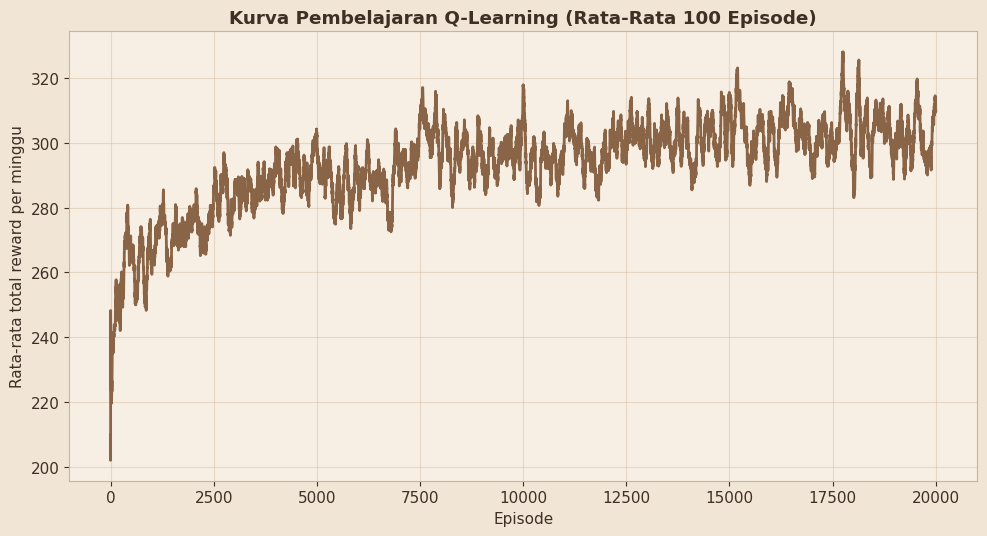

In [45]:
window_size = 100
rewards_ma = pd.Series(rewards_per_episode).rolling(window=window_size, min_periods=1).mean()

plt.figure(figsize=(10, 5.5))
plt.plot(rewards_ma, color=COK, linewidth=2)
plt.title(f"Kurva Pembelajaran Q-Learning (Rata-Rata {window_size} Episode)")
plt.xlabel("Episode")
plt.ylabel("Rata-rata total reward per minggu")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("static/results/kurva_pembelajaran.png", dpi=150)
plt.show()

Perkiraan episode konvergensi ditentukan sebagai episode pertama saat rata-rata bergerak mencapai 97% dari
rata-rata 1000 episode terakhir.

In [46]:
rata_awal = float(np.mean(rewards_per_episode[:100]))
rata_akhir = float(np.mean(rewards_per_episode[-1000:]))
mulai_konvergen = int(np.argmax(rewards_ma.values >= 0.97 * rata_akhir))

print(f"Rata-rata reward 100 episode pertama  : {rata_awal:.1f}")
print(f"Rata-rata reward 1000 episode terakhir: {rata_akhir:.1f}")
print(f"Perkiraan mulai konvergen di episode  : {mulai_konvergen}")

Rata-rata reward 100 episode pertama  : 242.0
Rata-rata reward 1000 episode terakhir: 301.9
Perkiraan mulai konvergen di episode  : 2740


**Cara membaca kurva**
- *Awal:* reward rendah dan tidak stabil karena ε masih tinggi sehingga tindakan agen banyak yang acak.
- *Tengah:* reward naik seiring ε menurun dan Q-Table mulai dipakai untuk memilih aksi.
- *Akhir:* reward mendatar. Fluktuasi kecil tetap ada karena permintaan harian acak.

## B6. Kebijakan optimal (policy)

Aksi terbaik pada tiap state adalah `argmax Q(s, a)`. Hasilnya ditampilkan sebagai tabel 4 (level stok) x 7 (hari).

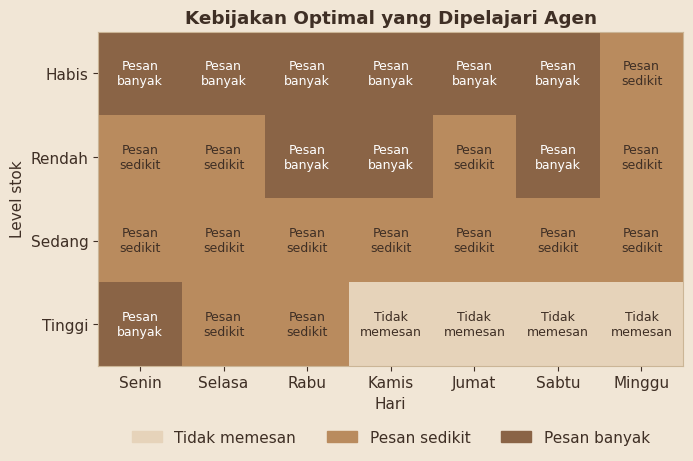

In [47]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

aksi_optimal = np.argmax(q_table, axis=1)
grid = np.zeros((4, 7), dtype=int)
for s in range(N_STATE):
    lv, hr = decode_state(s)
    grid[lv, hr] = aksi_optimal[s]

warna = [SUSU, KARAMEL, COK]
singkat = {0: "Tidak\nmemesan", 1: "Pesan\nsedikit", 2: "Pesan\nbanyak"}

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.imshow(grid, cmap=ListedColormap(warna), vmin=0, vmax=2)
for lv in range(4):
    for hr in range(7):
        a = grid[lv, hr]
        ax.text(hr, lv, singkat[a], ha="center", va="center", fontsize=9,
                color="white" if a == 2 else COK_TUA)
ax.set_xticks(range(7)); ax.set_xticklabels(HARI)
ax.set_yticks(range(4)); ax.set_yticklabels(LEVEL)
ax.set_xlabel("Hari"); ax.set_ylabel("Level stok")
ax.set_title("Kebijakan Optimal yang Dipelajari Agen")
ax.legend(handles=[Patch(color=warna[i], label=AKSI[i]) for i in range(3)],
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig("static/results/policy.png", dpi=150, bbox_inches="tight")
plt.show()

In [48]:
# Jumlah hari tiap aksi dipilih pada setiap level stok
ringkas = pd.DataFrame(
    [[(grid[lv] == a).sum() for a in range(3)] for lv in range(4)],
    index=LEVEL, columns=AKSI
)
ringkas.index.name = "Level stok"
ringkas

,Tidak memesan,Pesan sedikit,Pesan banyak
Level stok,,,
Habis,0,1,6
Rendah,0,4,3
Sedang,0,7,0
Tinggi,4,2,1


## B7. Perbandingan dengan strategi lain

Tiga strategi diuji pada 2000 minggu simulasi baru:
- **Acak:** aksi dipilih sembarang.
- **Aturan sederhana:** pesan banyak jika stok Habis, pesan sedikit jika Rendah, selain itu tidak memesan.
- **Agen Q-Learning:** mengikuti kebijakan hasil pelatihan tanpa eksplorasi.

In [49]:
def evaluasi(pilih_aksi, n_episode=2000, seed=2024):
    env_uji = CoffeeStockEnv(permintaan, seed=seed)
    total, kehabisan = [], []
    for _ in range(n_episode):
        s = env_uji.reset()
        r_total, habis = 0, 0
        for _ in range(7):
            s, r, done, info = env_uji.step(pilih_aksi(s))
            r_total += r
            habis += int(info["stok_habis"])
            if done:
                break
        total.append(r_total)
        kehabisan.append(habis)
    return float(np.mean(total)), float(np.mean(kehabisan))

pengacak = np.random.default_rng(7)
strategi = {
    "Acak": lambda s: int(pengacak.integers(N_AKSI)),
    "Aturan sederhana": lambda s: {0: 2, 1: 1, 2: 0, 3: 0}[decode_state(s)[0]],
    "Agen Q-Learning": lambda s: int(np.argmax(q_table[s])),
}

hasil = {}
for nama, fungsi in strategi.items():
    reward_rata, habis_rata = evaluasi(fungsi)
    hasil[nama] = {"reward_rata_rata": round(reward_rata, 1), "hari_stok_habis_rata_rata": round(habis_rata, 2)}

perbandingan = pd.DataFrame(hasil).T
perbandingan.columns = ["Reward rata-rata per minggu", "Hari stok habis per minggu"]
perbandingan

,Reward rata-rata per minggu,Hari stok habis per minggu
Acak,252.4,1.26
Aturan sederhana,284.5,0.94
Agen Q-Learning,304.2,0.19


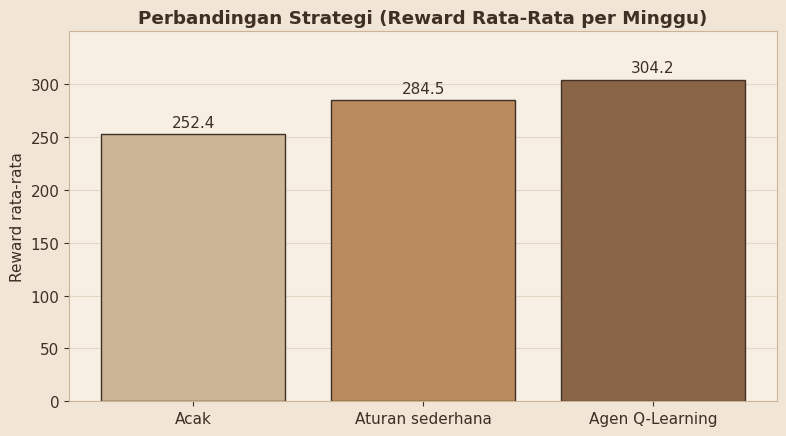

In [50]:
fig, ax = plt.subplots(figsize=(8, 4.5))
batang = ax.bar(perbandingan.index, perbandingan.iloc[:, 0], color=[PASIR, KARAMEL, COK], edgecolor=COK_TUA)
ax.set_title("Perbandingan Strategi (Reward Rata-Rata per Minggu)")
ax.set_ylabel("Reward rata-rata")
ax.bar_label(batang, fmt="%.1f", padding=3)
ax.set_ylim(0, perbandingan.iloc[:, 0].max() * 1.15)
ax.grid(axis="y", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("static/results/perbandingan_strategi.png", dpi=150)
plt.show()

## B8. Tingkat keyakinan terhadap kebijakan

Keyakinan tiap state dinilai dari dua hal: seberapa sering state itu dialami saat pelatihan, dan seberapa jauh selisih
nilai Q aksi terbaik dari aksi kedua. Aturan yang sama dipakai oleh aplikasi web.

| Tingkat | Syarat |
|---|---|
| tinggi | dikunjungi minimal 500 kali dan selisih minimal 3 |
| sedang | dikunjungi minimal 100 kali dan selisih minimal 1 |
| rendah | selain itu |

In [51]:
def tingkat_keyakinan(q_baris, kunjungan):
    urut = np.sort(q_baris)[::-1]
    selisih = urut[0] - urut[1]
    if kunjungan >= 500 and selisih >= 3:
        return "tinggi"
    if kunjungan >= 100 and selisih >= 1:
        return "sedang"
    return "rendah"

keyakinan = [tingkat_keyakinan(q_table[s], visit_counts[s].sum()) for s in range(N_STATE)]
sebaran_keyakinan = pd.Series(keyakinan).value_counts().reindex(["tinggi", "sedang", "rendah"], fill_value=0)
print("Jumlah state per tingkat keyakinan:")
print(sebaran_keyakinan.to_string())

Jumlah state per tingkat keyakinan:
tinggi    24
sedang     4
rendah     0


## B9. Penyimpanan model

In [52]:
np.save("model/q_table.npy", q_table)
np.save("model/visit_counts.npy", visit_counts)
np.save("model/reward_per_episode.npy", np.array(rewards_per_episode))

config = {
    "hiperparameter": {"alpha_awal": alpha_awal, "alpha_min": alpha_min, "alpha_decay": alpha_decay,
                       "gamma": gamma, "total_episodes": total_episodes,
                       "epsilon_awal": max_epsilon, "epsilon_min": min_epsilon, "decay_rate": decay_rate},
    "lingkungan": {"kapasitas": env.kapasitas, "pesan_sedikit": env.jumlah_pesan[1],
                   "pesan_banyak": env.jumlah_pesan[2]},
    "perkiraan_mulai_konvergen": mulai_konvergen,
    "evaluasi": hasil,
}
with open("model/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Tersimpan: model/q_table.npy, model/visit_counts.npy, model/reward_per_episode.npy, model/config.json")

Tersimpan: model/q_table.npy, model/visit_counts.npy, model/reward_per_episode.npy, model/config.json


## B10. Ringkasan temuan Bagian B

In [53]:
r_acak = hasil["Acak"]["reward_rata_rata"]
r_aturan = hasil["Aturan sederhana"]["reward_rata_rata"]
r_agen = hasil["Agen Q-Learning"]["reward_rata_rata"]
h_acak = hasil["Acak"]["hari_stok_habis_rata_rata"]
h_agen = hasil["Agen Q-Learning"]["hari_stok_habis_rata_rata"]

print(f"- Reward rata-rata per minggu naik dari {rata_awal:.1f} (100 episode pertama) menjadi {rata_akhir:.1f} (1000 episode terakhir).")
print(f"- Kurva mulai mendatar sekitar episode {mulai_konvergen}.")
print(f"- Agen Q-Learning memperoleh {r_agen:.1f} per minggu, dibanding aturan sederhana {r_aturan:.1f} dan strategi acak {r_acak:.1f}.")
print(f"- Hari stok habis per minggu turun dari {h_acak:.2f} (acak) menjadi {h_agen:.2f} (agen).")
for lv in range(4):
    dominan = AKSI[int(np.argmax(ringkas.iloc[lv].values))]
    print(f"- Pada stok {LEVEL[lv]}, aksi yang paling sering dipilih: {dominan.lower()}.")
print(f"- Tingkat keyakinan: {sebaran_keyakinan['tinggi']} state tinggi, {sebaran_keyakinan['sedang']} sedang, {sebaran_keyakinan['rendah']} rendah.")
print("- State dengan keyakinan rendah jarang dialami atau nilainya berdekatan, sehingga aksinya perlu dibaca sebagai petunjuk.")

- Reward rata-rata per minggu naik dari 242.0 (100 episode pertama) menjadi 301.9 (1000 episode terakhir).
- Kurva mulai mendatar sekitar episode 2740.
- Agen Q-Learning memperoleh 304.2 per minggu, dibanding aturan sederhana 284.5 dan strategi acak 252.4.
- Hari stok habis per minggu turun dari 1.26 (acak) menjadi 0.19 (agen).
- Pada stok Habis, aksi yang paling sering dipilih: pesan banyak.
- Pada stok Rendah, aksi yang paling sering dipilih: pesan sedikit.
- Pada stok Sedang, aksi yang paling sering dipilih: pesan sedikit.
- Pada stok Tinggi, aksi yang paling sering dipilih: tidak memesan.
- Tingkat keyakinan: 24 state tinggi, 4 sedang, 0 rendah.
- State dengan keyakinan rendah jarang dialami atau nilainya berdekatan, sehingga aksinya perlu dibaca sebagai petunjuk.


# BAGIAN C - Eksperimen Hiperparameter: Pengaruh Learning Rate (α)

Eksperimen memvariasikan satu hiperparameter, yaitu **α (learning rate)**. Parameter lain (γ, jumlah episode, ε,
dan lingkungan) dibuat sama agar perbedaan hasil hanya berasal dari α.

| Model | Pengaturan α |
|---|---|
| Default | menurun dari 0,3 ke 0,01 (sama dengan Bagian B) |
| Ekstrem rendah | tetap 0,001 |
| Ekstrem tinggi (tambahan) | tetap 0,9 |

## C1. Fungsi pelatihan dan evaluasi

In [54]:
def latih(a_awal, a_min, a_decay, gamma_x=gamma, episodes=total_episodes, seed=42):
    env_x = CoffeeStockEnv(permintaan, seed=seed)
    rng_x = np.random.default_rng(seed + 1)
    q = np.zeros((N_STATE, N_AKSI))
    eps = max_epsilon
    rewards = []

    for ep in range(episodes):
        a = max(a_min, a_awal * np.exp(-a_decay * ep))
        s = env_x.reset()
        total = 0
        for _ in range(max_steps_per_episode):
            if rng_x.random() < eps:
                act = int(rng_x.integers(N_AKSI))
            else:
                act = int(np.argmax(q[s]))
            s2, r, done, _ = env_x.step(act)
            target = r if done else r + gamma_x * np.max(q[s2])
            q[s, act] = (1 - a) * q[s, act] + a * target
            s = s2
            total += r
            if done:
                break
        rewards.append(total)
        eps = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * ep)
    return q, np.array(rewards)

def evaluasi_q(q, n_episode=2000, seed=2024):
    env_uji = CoffeeStockEnv(permintaan, seed=seed)
    total, kehabisan = [], []
    for _ in range(n_episode):
        s = env_uji.reset()
        r_total, habis = 0, 0
        for _ in range(7):
            s, r, done, info = env_uji.step(int(np.argmax(q[s])))
            r_total += r
            habis += int(info["stok_habis"])
            if done:
                break
        total.append(r_total)
        kehabisan.append(habis)
    return float(np.mean(total)), float(np.mean(kehabisan))

## C2. Pelatihan tiga model

In [55]:
konfigurasi = {
    "α default (menurun 0,3 ke 0,01)": (alpha_awal, alpha_min, alpha_decay),
    "α sangat rendah (tetap 0,001)": (0.001, 0.001, 0.0),
    "α sangat tinggi (tetap 0,9)": (0.9, 0.9, 0.0),
}

model = {}
for nama, (a_awal, a_min, a_decay) in konfigurasi.items():
    q, rewards = latih(a_awal, a_min, a_decay)
    reward_eval, habis_eval = evaluasi_q(q)
    model[nama] = {"alpha": a_awal, "q": q, "rewards": rewards,
                   "reward_eval": reward_eval, "habis_eval": habis_eval}
    print(f"{nama:34s} selesai | reward evaluasi: {reward_eval:.1f}")

α default (menurun 0,3 ke 0,01)    selesai | reward evaluasi: 306.6
α sangat rendah (tetap 0,001)      selesai | reward evaluasi: 297.2
α sangat tinggi (tetap 0,9)        selesai | reward evaluasi: 298.0


## C3. Perbandingan kurva pembelajaran

Garis yang naik lebih lambat menunjukkan pembelajaran yang lebih lambat. Garis yang lebih bergelombang atau
berhenti pada angka lebih rendah menunjukkan pembelajaran yang kurang stabil.

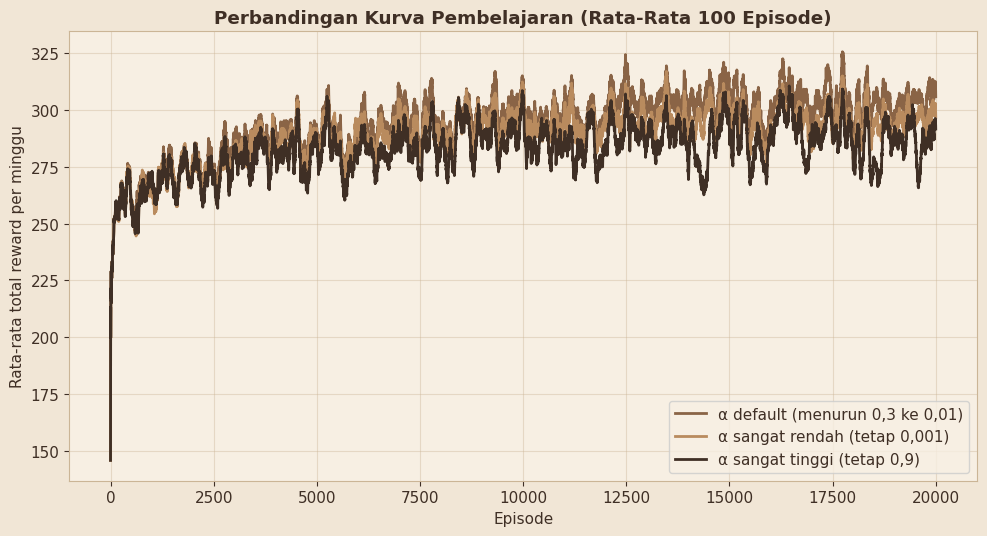

In [56]:
warna_garis = dict(zip(model.keys(), [COK, KARAMEL, COK_TUA]))

plt.figure(figsize=(10, 5.5))
for nama, m in model.items():
    ma = pd.Series(m["rewards"]).rolling(window=window_size, min_periods=1).mean()
    plt.plot(ma, label=nama, color=warna_garis[nama], linewidth=2)
plt.title(f"Perbandingan Kurva Pembelajaran (Rata-Rata {window_size} Episode)")
plt.xlabel("Episode")
plt.ylabel("Rata-rata total reward per minggu")
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("static/results/eksperimen_alpha.png", dpi=150)
plt.show()

## C4. Perbandingan hasil akhir

In [57]:
baris = []
for nama, m in model.items():
    ma = pd.Series(m["rewards"]).rolling(window=window_size, min_periods=1).mean()
    baris.append({
        "Model": nama,
        "Reward di episode 1000": round(ma.iloc[999], 1),
        "Reward 1000 episode terakhir": round(m["rewards"][-1000:].mean(), 1),
        "Reward evaluasi (policy akhir)": round(m["reward_eval"], 1),
        "Hari stok habis per minggu": round(m["habis_eval"], 2),
    })
tabel = pd.DataFrame(baris).set_index("Model")
tabel

,Reward di episode 1000,Reward 1000 episode terakhir,Reward evaluasi (policy akhir),Hari stok habis per minggu
Model,,,,
"α default (menurun 0,3 ke 0,01)",271.9,304.6,306.6,0.18
"α sangat rendah (tetap 0,001)",268.7,296.3,297.2,0.39
"α sangat tinggi (tetap 0,9)",272.0,286.8,298.0,0.26


In [58]:
# Jumlah state (dari 28) yang aksi terbaiknya berbeda dari model default
nama_default = list(model.keys())[0]
policy_default = np.argmax(model[nama_default]["q"], axis=1)
beda_policy = {}
for nama, m in model.items():
    beda_policy[nama] = int((np.argmax(m["q"], axis=1) != policy_default).sum())
    print(f"{nama:34s} -> {beda_policy[nama]} dari 28 state berbeda dari model default")

α default (menurun 0,3 ke 0,01)    -> 0 dari 28 state berbeda dari model default
α sangat rendah (tetap 0,001)      -> 12 dari 28 state berbeda dari model default
α sangat tinggi (tetap 0,9)        -> 11 dari 28 state berbeda dari model default


## C5. Penyimpanan hasil eksperimen

In [59]:
nama_rendah = list(model.keys())[1]
np.save("model/q_table_eksperimen.npy", model[nama_rendah]["q"])

hasil_eksperimen = {nama: {"alpha": m["alpha"],
                           "reward_evaluasi": round(m["reward_eval"], 1),
                           "hari_stok_habis": round(m["habis_eval"], 2),
                           "reward_1000_episode_terakhir": round(float(m["rewards"][-1000:].mean()), 1)}
                    for nama, m in model.items()}
with open("model/eksperimen.json", "w", encoding="utf-8") as f:
    json.dump(hasil_eksperimen, f, ensure_ascii=False, indent=2)
print("Tersimpan: model/q_table_eksperimen.npy, model/eksperimen.json")

Tersimpan: model/q_table_eksperimen.npy, model/eksperimen.json


## C6. Ringkasan temuan Bagian C

Interpretasi umum:
- **α sangat rendah** memperbarui Q-Table sangat lambat, sehingga nilai Q masih kecil dan belum matang pada akhir pelatihan.
- **α sangat tinggi** hampir sepenuhnya menimpa nilai lama dengan pengalaman terbaru. Pada lingkungan yang acak,
  satu hari yang kebetulan ramai atau sepi dapat menggeser Q-Table terlalu jauh sehingga hasil menjadi tidak stabil.
- **α menurun** memadukan pembelajaran cepat di awal dan kestabilan di akhir.

In [60]:
n_def, n_rendah, n_tinggi = list(model.keys())
r_def = model[n_def]["reward_eval"]
r_rendah = model[n_rendah]["reward_eval"]
r_tinggi = model[n_tinggi]["reward_eval"]

print(f"- Reward evaluasi: default {r_def:.1f}, α sangat rendah {r_rendah:.1f} ({r_rendah - r_def:+.1f}), α sangat tinggi {r_tinggi:.1f} ({r_tinggi - r_def:+.1f}).")
print(f"- Jumlah state dengan aksi terbaik berbeda dari default: α sangat rendah {beda_policy[n_rendah]} dari 28, α sangat tinggi {beda_policy[n_tinggi]} dari 28.")
terbaik = max(model, key=lambda k: model[k]["reward_eval"])
print(f"- Reward evaluasi tertinggi dicapai oleh model: {terbaik}.")

- Reward evaluasi: default 306.6, α sangat rendah 297.2 (-9.4), α sangat tinggi 298.0 (-8.7).
- Jumlah state dengan aksi terbaik berbeda dari default: α sangat rendah 12 dari 28, α sangat tinggi 11 dari 28.
- Reward evaluasi tertinggi dicapai oleh model: α default (menurun 0,3 ke 0,01).


## Penutup

Seluruh keluaran yang dibutuhkan aplikasi web tersimpan di folder `model/` dan `static/results/`:
`q_table.npy`, `visit_counts.npy`, `config.json`, `eksperimen.json`, serta grafik hasil pelatihan.